# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import ERADataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

New dataset split

In [ ]:
dataset_config = {
    "data_dir": "./data/ERA/SingleFrames/",
    "csv_file": "./data/ERA/SingleFrames/splits_final/era_train.csv"
}
dataset = ERADataset(dataset_config)
print(len(dataset))

1718


Original dataset split

In [ ]:
dataset_config = {
    "data_dir": "./data/ERA/SingleFrames/Tra/",
}
dataset = ERADataset(dataset_config)
print(len(dataset))

1473


## Show images from the dataset

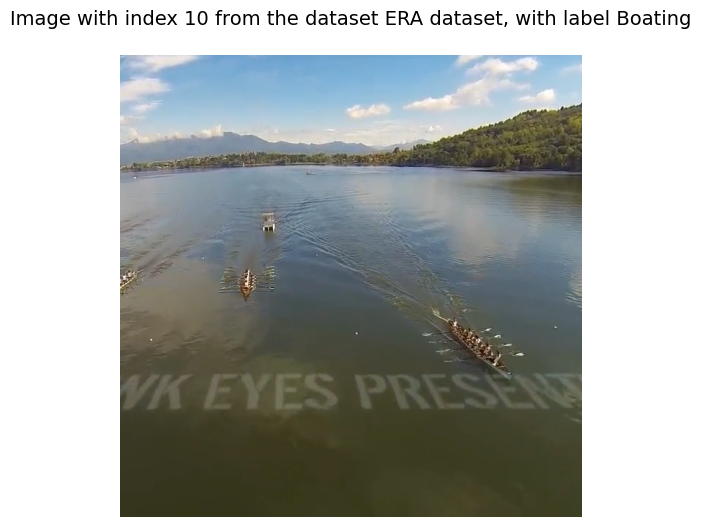

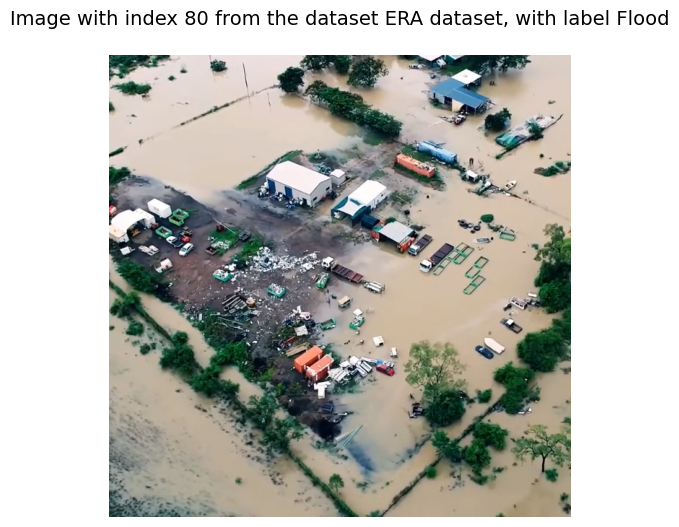

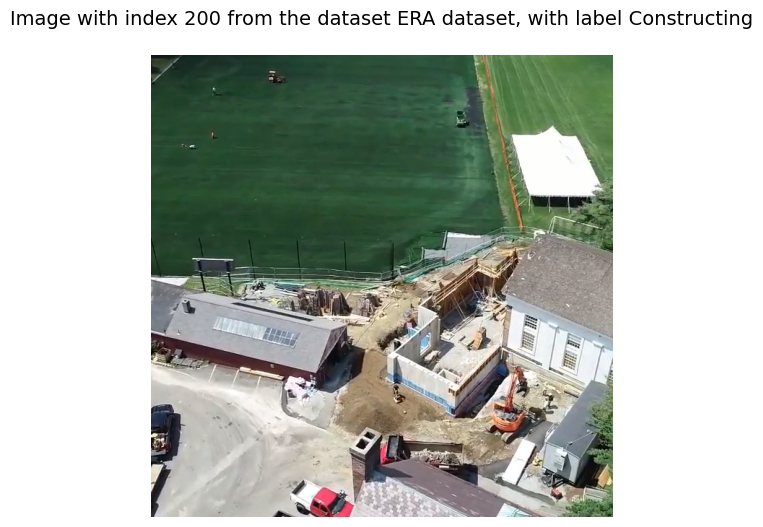

In [8]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

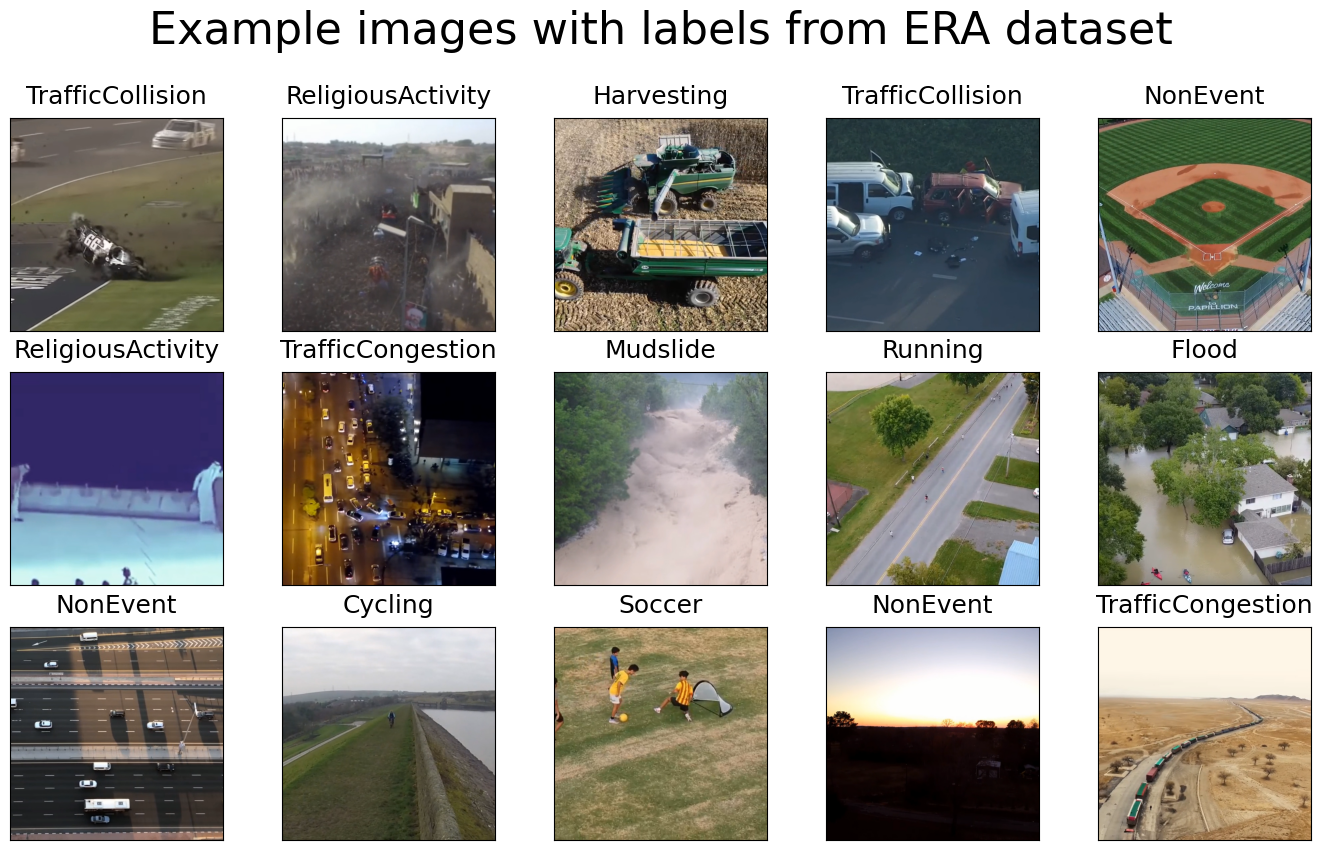

In [23]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [14]:
dataset.data_distribution_table()

,Label,Count
0,Baseball,51
1,Basketball,52
2,Boating,52
3,CarRacing,26
4,Concert,51
5,Conflict,25
6,Constructing,59
7,Cycling,56
8,Fire,58
9,Flood,51


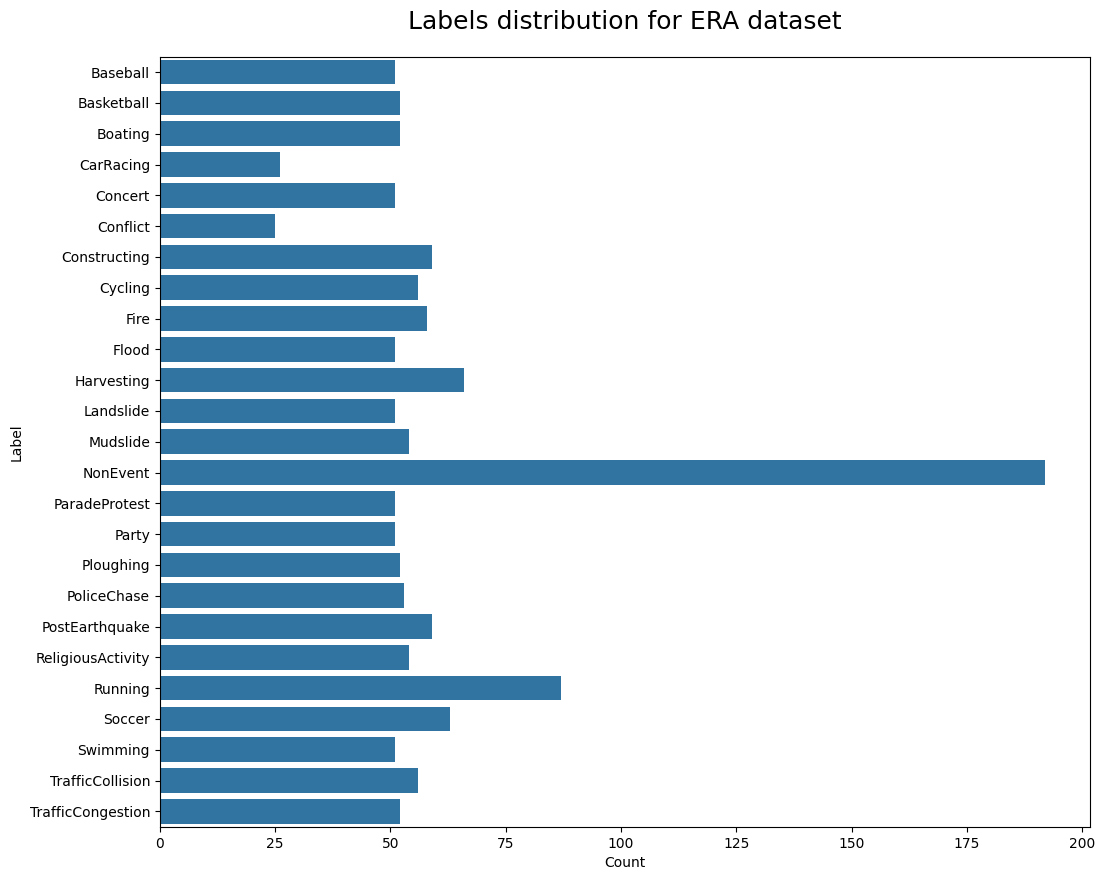

In [43]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/ERA/SingleFrames/Tra/"
}

train_dataset = ERADataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/ERA/SingleFrames/Test/",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = ERADataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(1473, 1391)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/ERA/"
model_config = {
    "num_classes": 25, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-20 12:06:29,754 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-20 12:06:30,201 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [7]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-20 12:06:30,266 INFO Starting training.
training: 100%|██████████| 47/47 [00:26<00:00,  1.78it/s]
2025-05-20 12:06:56,966 INFO epoch: 1, time: 26, loss:  2.90573
testing on train set: 100%|██████████| 47/47 [00:10<00:00,  4.70it/s]
2025-05-20 12:07:08,837 INFO Accuracy:0.5023761031907671, Precision Micro:0.5023761031907671, Precision Macro:0.5727580829949545, Precision Weighted:0.5554092832126208, Precision per Class:[0.81818182 0.94285714 0.56338028 1.         0.72       0.
 0.73333333 0.40506329 0.54320988 0.83333333 0.64102564 0.32
 0.45454545 0.35860058 0.4125     0.5625     1.         0.63793103
 0.37142857 0.54761905 0.62       0.51785714 0.44927536 0.45454545
 0.41176471], Recall Micro:0.5023761031907671, Recall Macro:0.45866610336328256, Recall Weighted:0.5023761031907671, Recall per Class:[0.52941176 0.63461538 0.76923077 0.03846154 0.70588235 0.
 0.37288136 0.57142857 0.75862069 0.09803922 0.37878788 0.15686275
 0.09259259 0.640625   0.64705882 0.17647059 0.28846154 0

0.026003651460032032

## Predictions

2025-05-20 12:13:51,324 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/ERA/checkpoint.pth.tar
2025-05-20 12:13:52,085 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/ERA/checkpoint.pth.tar at epoch 11


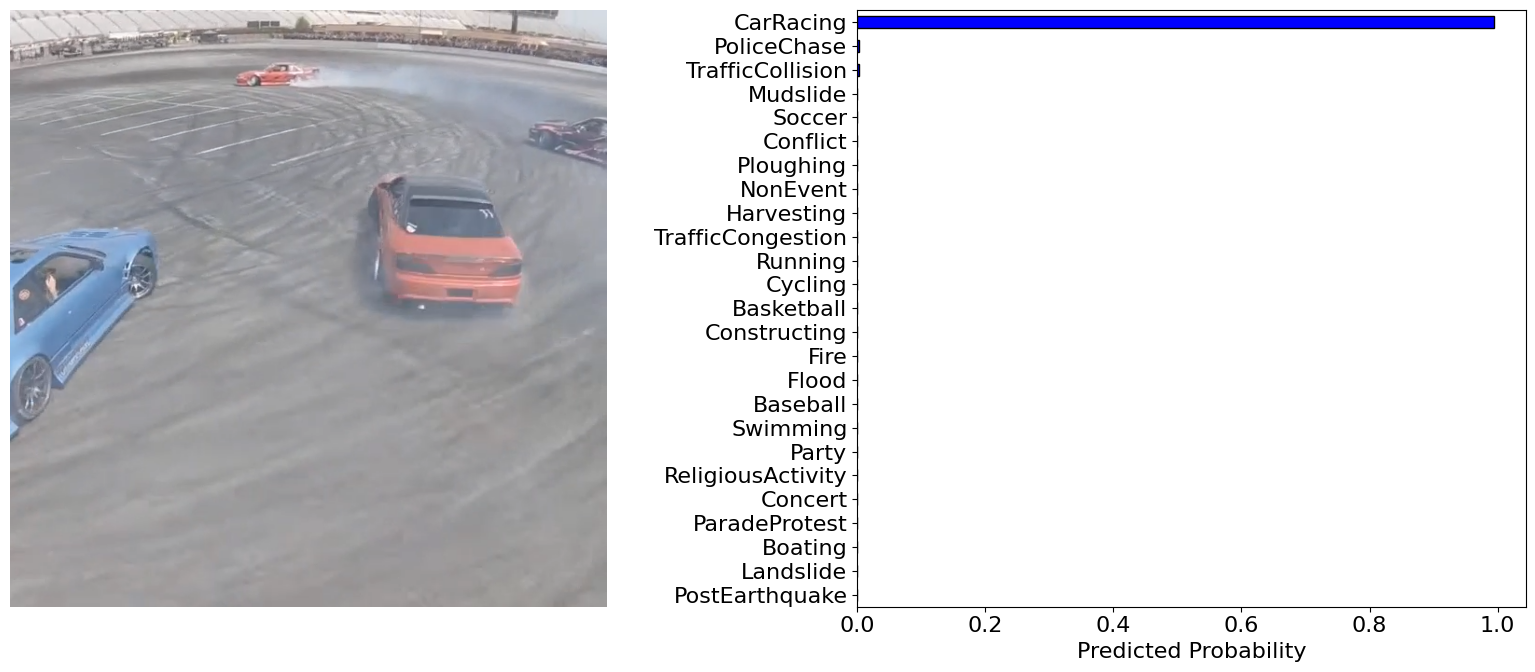

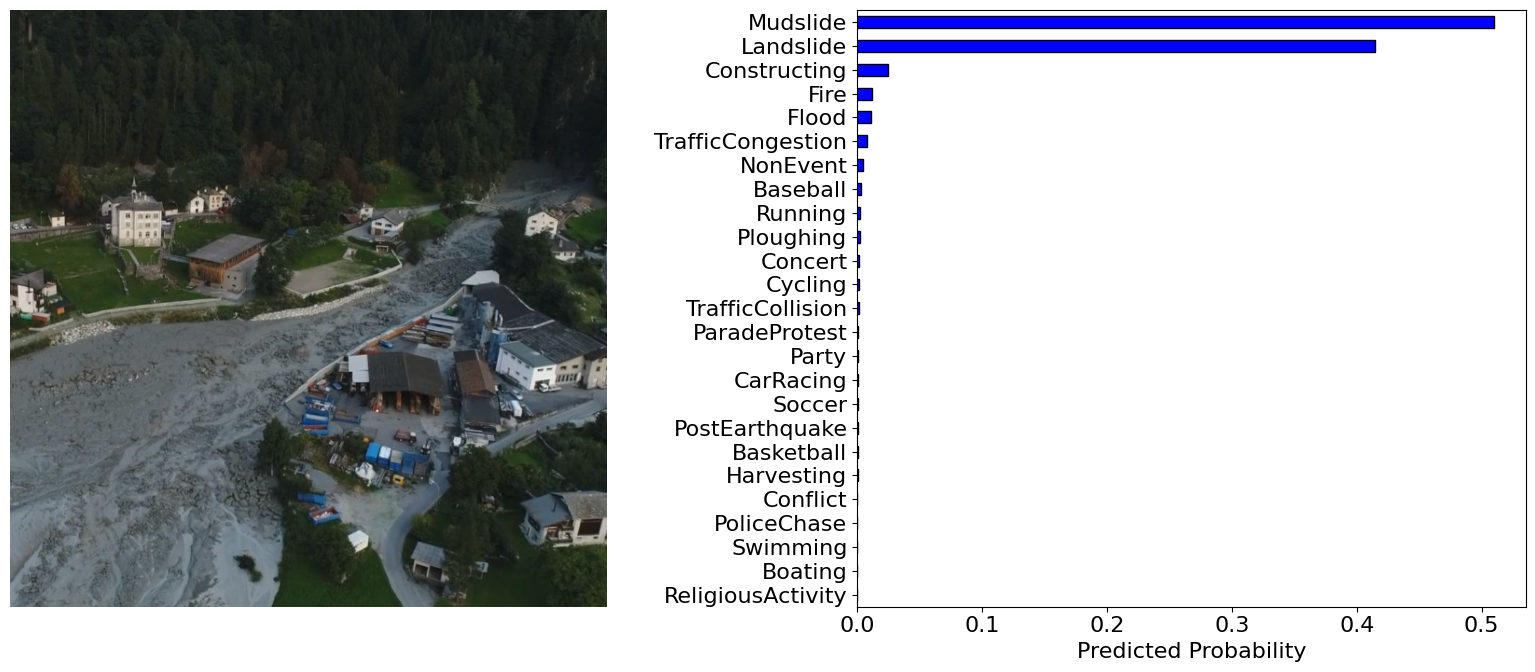

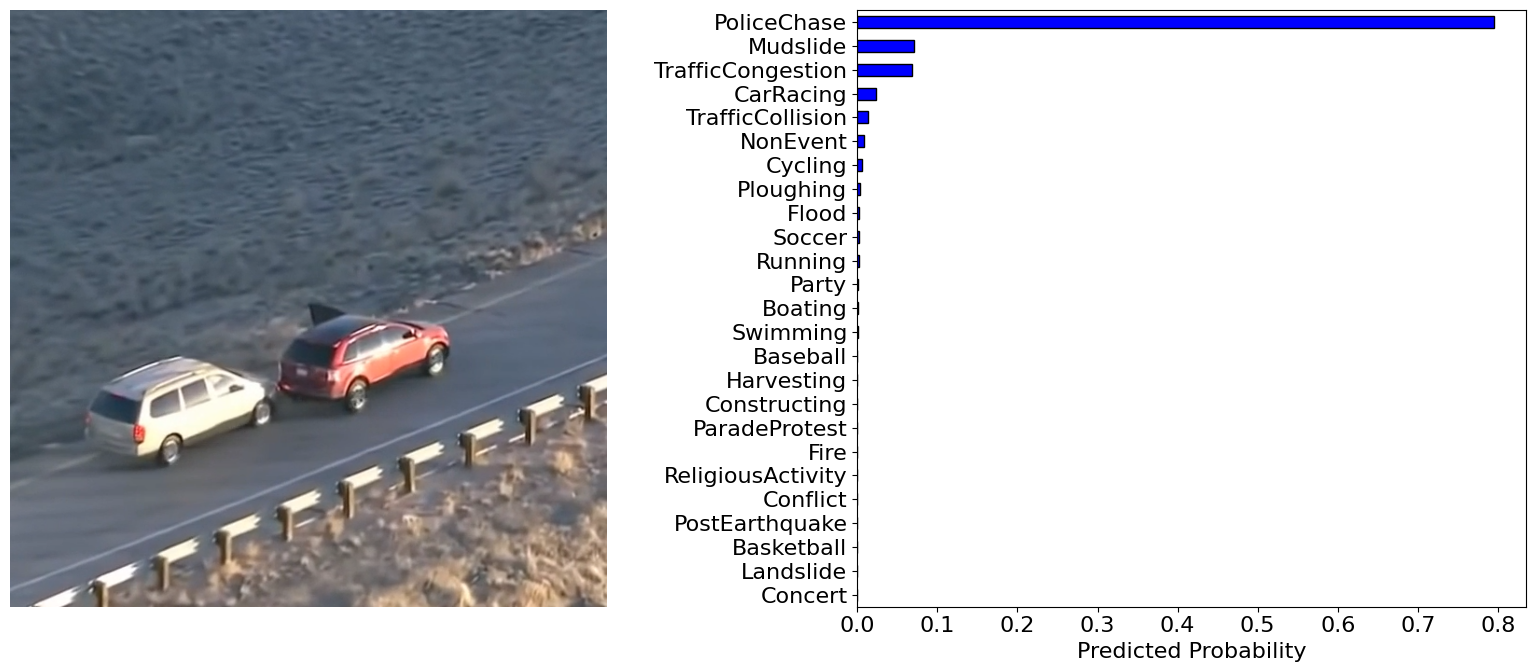

In [ ]:
labels = ["Baseball","Basketball","Boating","CarRacing","Concert","Conflict","Constructing","Cycling",
          "Fire","Flood","Harvesting","Landslide","Mudslide","NonEvent","ParadeProtest","Party","Ploughing",
          "PoliceChase","PostEarthquake","ReligiousActivity","Running","Soccer","Swimming","TrafficCollision",
          "TrafficCongestion"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/ERA/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader("./data/ERA/SingleFrames/Test/CarRacing/CarRacing_004 .png")
fig = model.predict_image(image, labels, transform)

image = image_loader("./data/ERA/SingleFrames/Test/Mudslide/Mudslide_009 .png")
fig = model.predict_image(image, labels, transform)

image = image_loader("./data/ERA/SingleFrames/Test/PoliceChase/PoliceChase_009 .png")
fig = model.predict_image(image, labels, transform)